<a href="https://colab.research.google.com/github/KayotPoziloy/mushrooms-ml-research/blob/main/research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Загрузка данных

In [1]:
# @title
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "mushrooms.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "uciml/mushroom-classification",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

Using Colab cache for faster access to the 'mushroom-classification' dataset.


In [2]:
raw_df = df.copy()

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)


## EDA

In [4]:
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,p,w,o,e,n,a,g


In [5]:
df.shape

(8124, 23)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [7]:
df.describe().T

,count,unique,top,freq
class,8124,2,e,4208
cap-shape,8124,6,x,3656
cap-surface,8124,4,y,3244
cap-color,8124,10,n,2284
bruises,8124,2,f,4748
odor,8124,9,n,3528
gill-attachment,8124,2,f,7914
gill-spacing,8124,2,c,6812
gill-size,8124,2,b,5612
gill-color,8124,12,b,1728


предварительно вижу, что все наборы категориальные, нужно будет кодировать

In [8]:
df.duplicated().sum()

np.int64(0)

veil-type имеет всего одну категорию, поэтому этот параметр можно дропнуть

In [9]:
df = df.drop(columns='veil-type')
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,w,o,e,n,a,g


In [10]:
for column in df.columns:
  print(f'{column}:\n{df[column].unique()}')
  print('\n', '-'*100, '\n')

class:
['p' 'e']

 ---------------------------------------------------------------------------------------------------- 

cap-shape:
['x' 'b' 's' 'f' 'k' 'c']

 ---------------------------------------------------------------------------------------------------- 

cap-surface:
['s' 'y' 'f' 'g']

 ---------------------------------------------------------------------------------------------------- 

cap-color:
['n' 'y' 'w' 'g' 'e' 'p' 'b' 'u' 'c' 'r']

 ---------------------------------------------------------------------------------------------------- 

bruises:
['t' 'f']

 ---------------------------------------------------------------------------------------------------- 

odor:
['p' 'a' 'l' 'n' 'f' 'c' 'y' 's' 'm']

 ---------------------------------------------------------------------------------------------------- 

gill-attachment:
['f' 'a']

 ---------------------------------------------------------------------------------------------------- 

gill-spacing:
['c' 'w']

 -----------

в `stalk-root` вижу категорию `'?'`, означает, что корень отсутствует, лучше подписать `missing`

In [11]:
df['stalk-root'] = df['stalk-root'].replace('?', 'missing')

gill-attachment, veil-color, ring-number - почти константные, нужно проверить распределение

In [12]:
display(df['gill-attachment'].value_counts())
display(df['gill-attachment'].value_counts().iloc[0] / df.shape[0] * 100)
display(df['veil-color'].value_counts())
display(df['veil-color'].value_counts().iloc[0] / df.shape[0] * 100)
display(df['ring-number'].value_counts())
display(df['ring-number'].value_counts().iloc[0] / df.shape[0] * 100)

,count
gill-attachment,
f,7914
a,210


np.float64(97.41506646971935)

,count
veil-color,
w,7924
n,96
o,96
y,8


np.float64(97.53815854258985)

,count
ring-number,
o,7488
t,600
n,36


np.float64(92.17134416543574)

- gill-attachment (крепление пластинок): attached=a (приросшие),free=f (свободные)
- veil-color (цвет покрывала): brown=n,orange=o,white=w,yellow=y
- ring-number (количество колец на ножке): none=n,one=o,two=t

Предварительно кажется, что эти параметры полезные, стоит проверить, как они связаны с таргетом.

In [13]:
pd.crosstab(df["veil-color"], df["class"])

class,e,p
veil-color,,
n,96,0
o,96,0
w,4016,3908
y,0,8


In [14]:
pd.crosstab(df["gill-attachment"], df["class"])

class,e,p
gill-attachment,,
a,192,18
f,4016,3898


In [15]:
pd.crosstab(df["ring-number"], df["class"])

class,e,p
ring-number,,
n,0,36
o,3680,3808
t,528,72


Признаки `veil-color`, `gill-attachment` и `ring-number` на некоторых категориях почти со 100% точностью указывают таргет. Но выборки в этих классах довольно мелкие, поэтому на новых данных все может измениться, а значит сейчас есть риск переобучения, что стоит учитывать при обучении модели в дальнейшем

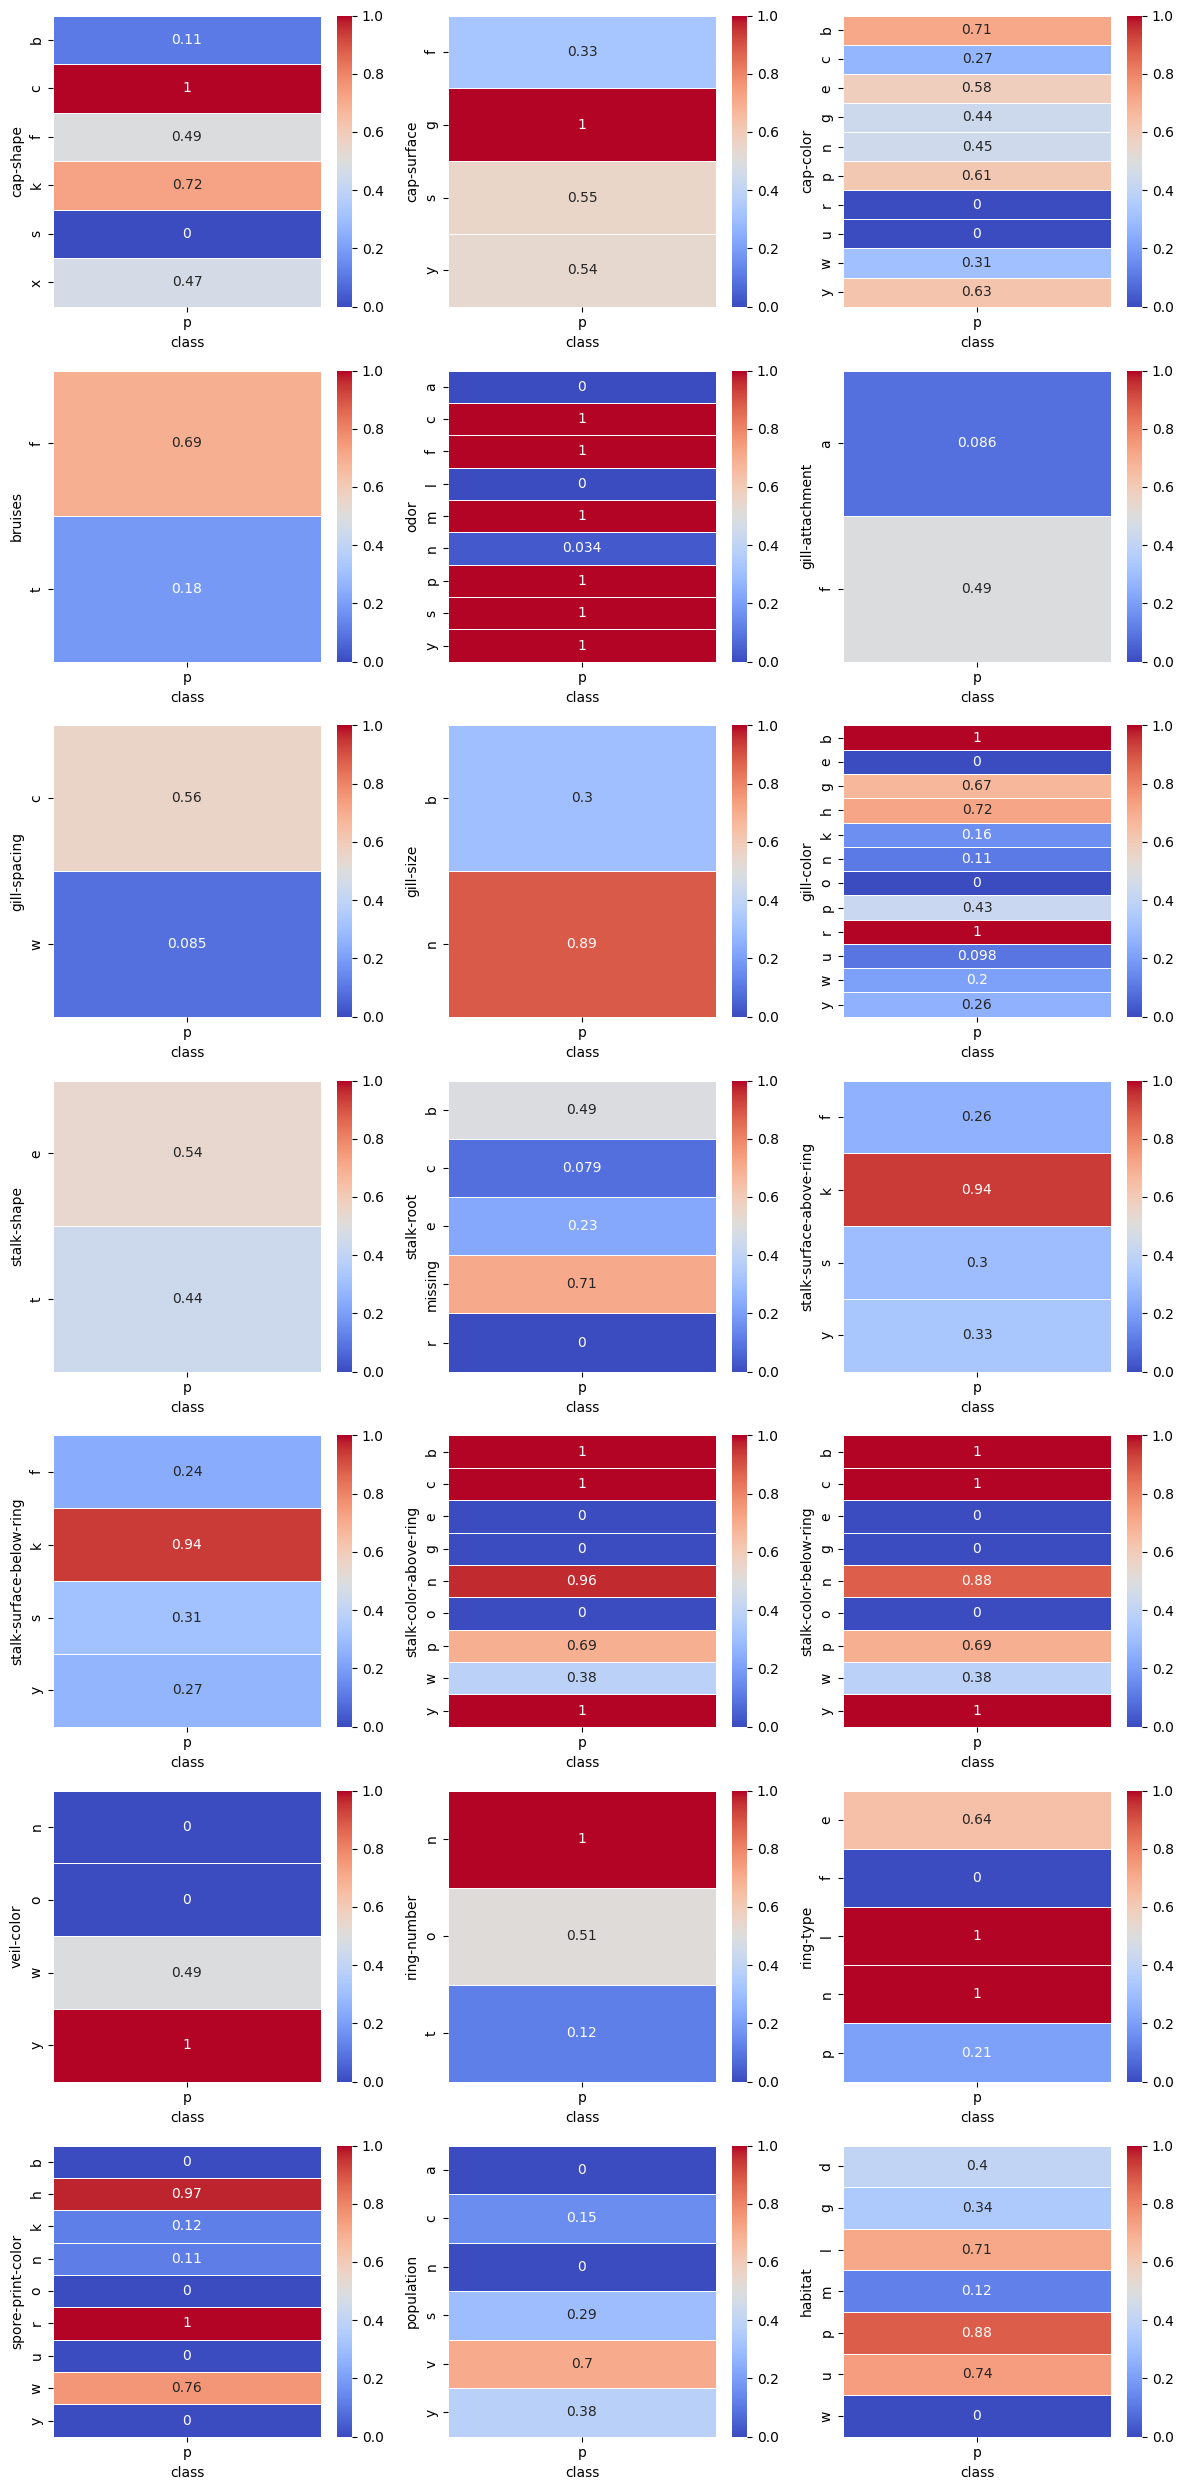

In [16]:
fig, axes = plt.subplots(7, 3, figsize=(12, 25))

axes_flat = axes.flatten()

for i, column in enumerate(df.drop(columns='class').columns):
  ct = pd.crosstab(df[column], df['class'], normalize='index')

  sns.heatmap(
    ct[['p']],
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    ax=axes_flat[i],
    vmin=0, vmax=1
  )
plt.tight_layout()



Отдельно рассмотрим признаки, которые бросаются в глаза как сильные

In [17]:
interesting_columns = [
    'odor',
    'gill-size',
    'gill-color',
    'veil-color',
    'stalk-color-above-ring',
    'spore-print-color'
    ]

for column in interesting_columns:
  ct = pd.crosstab(df[column], df['class'])

  display(ct)


class,e,p
odor,,
a,400,0
c,0,192
f,0,2160
l,400,0
m,0,36
n,3408,120
p,0,256
s,0,576
y,0,576


class,e,p
gill-size,,
b,3920,1692
n,288,2224


class,e,p
gill-color,,
b,0,1728
e,96,0
g,248,504
h,204,528
k,344,64
n,936,112
o,64,0
p,852,640
r,0,24


class,e,p
veil-color,,
n,96,0
o,96,0
w,4016,3908
y,0,8


class,e,p
stalk-color-above-ring,,
b,0,432
c,0,36
e,96,0
g,576,0
n,16,432
o,192,0
p,576,1296
w,2752,1712
y,0,8


class,e,p
spore-print-color,,
b,48,0
h,48,1584
k,1648,224
n,1744,224
o,48,0
r,0,72
u,48,0
w,576,1812
y,48,0


`odor` - самый сильный признак в датасете, т.к. он почти по каждой категории четко делит таргет

`stalk-color-above-ring` тоже хорошо делит таргет

### Распределение классов таргета

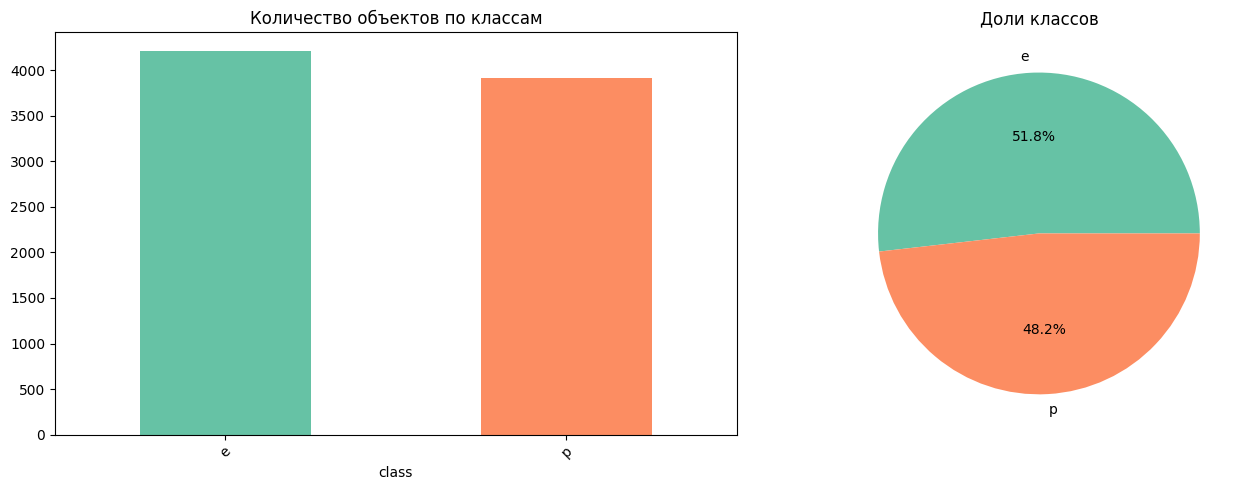

In [18]:
target_col = 'class'
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df[target_col].value_counts().plot.bar(ax=axes[0], color=sns.color_palette('Set2'))
axes[0].set_title('Количество объектов по классам')
axes[0].tick_params(axis='x', rotation=45)

df[target_col].value_counts(normalize=True).plot.pie(ax=axes[1], autopct='%1.1f%%', colors=sns.color_palette('Set2'))
axes[1].set_ylabel('')
axes[1].set_title('Доли классов')
plt.tight_layout()
plt.show()

распределение норм, можно использовать accuracy.

### Связь признаков

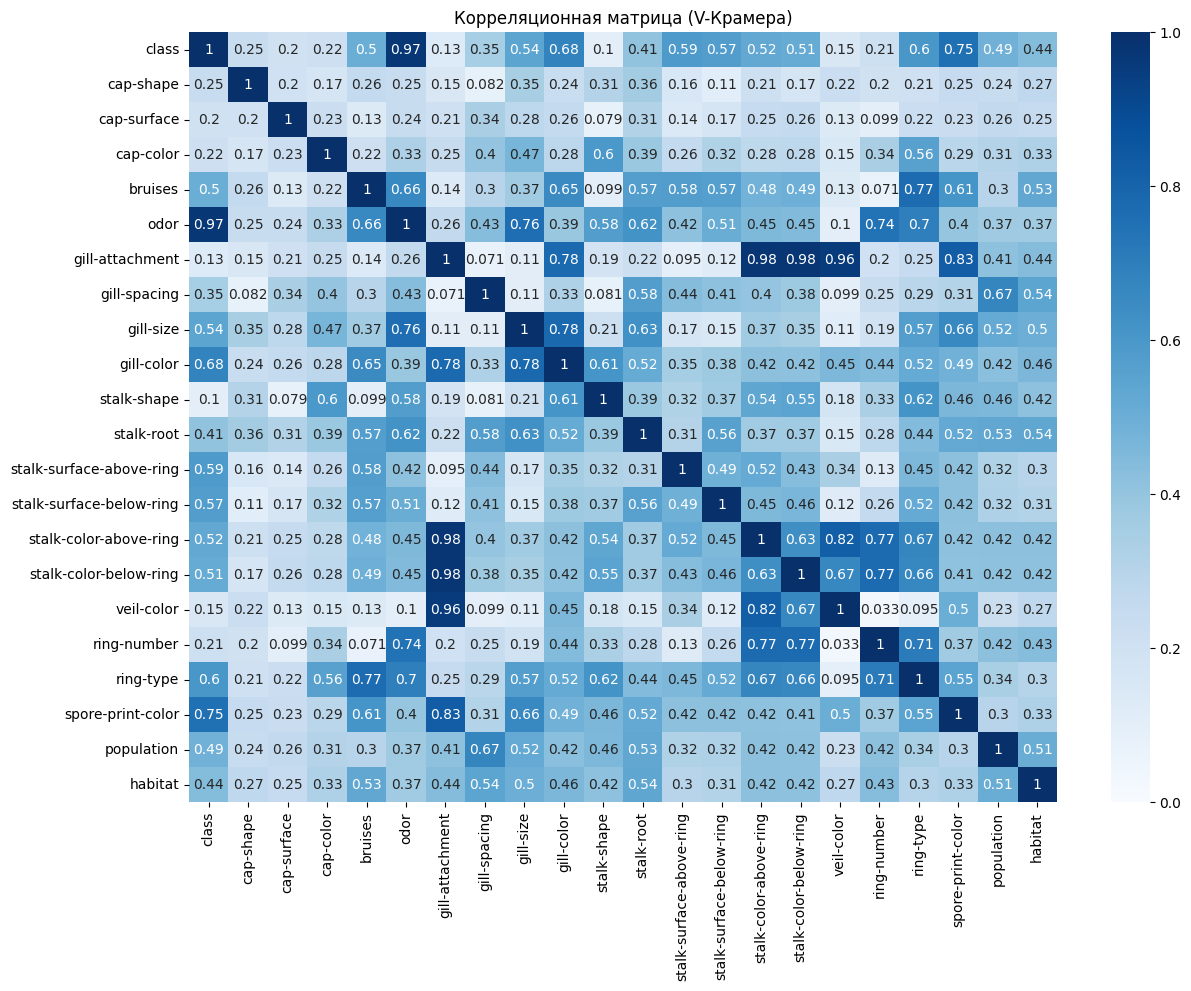

In [19]:
from scipy.stats import contingency

def cramers_v_matrix(data):
  cols = data.select_dtypes(include=['object', 'category']).columns
  corr_matrix = pd.DataFrame(index=cols, columns=cols, dtype=float)

  for col1 in cols:
    for col2 in cols:
      if col1 == col2:
        corr_matrix.loc[col1, col2] = 1.0
      else:
        ct = pd.crosstab(data[col1], data[col2])
        v = contingency.association(ct, method='cramer')
        corr_matrix.loc[col1, col2] = v

  return corr_matrix

cramers_df = cramers_v_matrix(df)

plt.figure(figsize=(14, 10))
sns.heatmap(cramers_df, annot=True, cmap='Blues', vmin=0, vmax=1)
plt.title("Корреляционная матрица (V-Крамера)")
plt.show()

Между `gill-attachment` и `stalk-color-above-ring`, `stalk-color-below-ring`, `veil-color` видим почти полную связь

In [20]:
corr_columns = [
    'veil-color',
    'stalk-color-above-ring',
    'stalk-color-below-ring'
    ]

for column in corr_columns:
  ct = pd.crosstab(df[column], df['gill-attachment'])

  display(ct)


gill-attachment,a,f
veil-color,,
n,96,0
o,96,0
w,18,7906
y,0,8


gill-attachment,a,f
stalk-color-above-ring,,
b,0,432
c,18,18
e,0,96
g,0,576
n,0,448
o,192,0
p,0,1872
w,0,4464
y,0,8


gill-attachment,a,f
stalk-color-below-ring,,
b,0,432
c,18,18
e,0,96
g,0,576
n,0,512
o,192,0
p,0,1872
w,0,4384
y,0,24


`gill-attachment` сильно связан с цветом ножки и покрывала гриба, он определяет редкие виды грибов, значит признакие не дублируют друг-друга, а у них просто общая редкая группа грибов, удалять этот параметр не стоит.

### Выводы по EDA
- удалили `veil-type`, тк всего одна категория.
- в `stalk-root` категорию `?` преобразовали в `missing`, тк `?` вызывает вопросы, хотя в описании датасета так просто обозначали отсутствие корня.
- выделяем признак `odor` как очень сильный признак, тк 8 из 9 категорий дают 100% конкретного класса.
- `gill-attachment` определяет редкую группу грибов (210 штук) с определенным цветом ножки и покрывала.
- `veil-color` и `ring-number` - почти константны, поэтому стоит учитывать риск переобучения на маленьких группах. Оставляем так-как однозначно определяют класс редких видов грибов.
- таргет `class` имеет сбалансированное распределение 52/48.

## Гипотезы

1. если обучим модель только на `odor`, accuracy будет около 0.985, recall по *`p`* около 0.97, потому что все запахи кроме *`n`* дают 100% одного класса.
2. Логистическая регрессия, обученная только на `odor`, при пороге 0.5 даст FN ≈ 24 (все ядовитые с запахом *`n`* с расчетом доли тестовой выборки 0.2). Если снизить порог для *`p`* до ~0.03, FN упадёт до 0, но FP вырастет с ~0 до ~680 (все съедобные с запахом *`n`*), потому что среди грибов с запахом *`n`* ядовитых всего 3.4%, и модель выдаёт для них вероятность около 0.034.
3. `odor` разделит 98% грибов. Но так как по некоторым признакам нам нужно отделить редкую группу грибов (например, на `veil-color` по 96 *`n`* *`o`*, и 210 на `gill-attachement` по *`a`* ), **будем считать, что на глубине 5 FN упадет до 0, на train и test разрыва не будет**.
4. Дерево решений (без ограничения глубины) отдаст `odor` около 90% важности. Большинство остальных признаков получат важность меньше 1%. Все это потому что первый разрез по `odor` (*`n`* и *не `n`*) снимет около 60% неопределенности, в одной ветке останется только отделить 120 ядовитых грибов с `odor` *`n`*, в другой скорее всего продолжится деление по `odor`, это 800 съедобных грибов с *`a`* или *`l`* и 3796 ядовитых грибов
5. Дерево решений без ограничений глубины, обученное на топ-4 целых признаках по V-Крамера с таргетом (на train), получит FN=0 по классу *`p`* (ядовитый) и accuracy близкую к 100%. На топ-3 ожидается FN > 0 и точность 99%. Ожидаемый топ-3: `odor`, `spore-print-color`, `gill-color`. Четвертым скорее всего `ring-type`, но может поменяться, потому что его корреляция (0.60) с таргетом близка к соседним (0.57-0.59). Причина: `odor` ошибается на 120 грибах по `n` (1.5% выбрки), их нужно разобрать другими признаками. `odor`, `spore-print-color`, `gill-color` сильно связаны с таргетом, поэтому ожидается, что они разобьют эти 120 грибов.


Краткая табличка по гипотезам

<table style="width:100%; table-layout:fixed;">
  <tr>
    <th style="width:5%">№</th>
    <th style="width:30%">Что делаем</th>
    <th style="width:35%">Что ожидаем</th>
    <th style="width:30%">Почему</th>
  </tr>
  <tr>
    <td>1</td>
    <td>Модель только на <code>odor</code></td>
    <td>accuracy ≈ 0.985, recall по <code>p</code> ≈ 0.97</td>
    <td>все запахи, кроме <code>n</code>, дают 100% одного класса</td>
  </tr>
  <tr>
    <td>2</td>
    <td>Логистическая регрессия на <code>odor</code>, порог для <code>p</code>: 0.5 → ≈0.03</td>
    <td>FN: ≈120 → ≈0, FP: ≈0 → ≈3400</td>
    <td>среди грибов с запахом <code>n</code> ядовитых 3.4%</td>
  </tr>
  <tr>
    <td>3</td>
    <td>Дерево, перебор <code>max_depth</code></td>
    <td>глубина ≤ 4: FN > 0; глубина 5: FN = 0 на train и test</td>
    <td>шума нет, но редкие группы требуют отдельных ветвей</td>
  </tr>
  <tr>
    <td>4</td>
    <td>Дерево без ограничения глубины, <code>feature_importances_</code></td>
    <td><code>odor</code> ≈ 90%, у большинства остальных < 1%</td>
    <td>первый разрез по <code>odor_n</code> снимает ≈60% неопределённости</td>
  </tr>
  <tr>
    <td>5</td>
    <td>Дерево на топ-K признаках по V-Крамера</td>
    <td>K = 4: FN = 0; K = 3: FN > 0, accuracy ≈ 99%</td>
    <td>120 ядовитых среди <code>n</code> разберут признаки, сильно связанные с классом</td>
  </tr>
</table>

# Подготовка данных

1. отделим `class` и закодируем p = 1, e = 0
2. разобьем датасет на test и train
3. зададим метод для создания пайплайна с кодированием и моделью


Масштабированием нам не нужно, т.к. все признаки категориальные

In [21]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

In [22]:
X = df.drop(columns='class')
y = df['class']
display(X)
display(y)

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,e,s,s,w,w,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,c,s,s,w,w,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,c,s,s,w,w,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,e,s,s,w,w,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,e,s,s,w,w,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,k,s,n,f,n,a,c,b,y,e,missing,s,s,o,o,o,o,p,b,c,l
8120,x,s,n,f,n,a,c,b,y,e,missing,s,s,o,o,n,o,p,b,v,l
8121,f,s,n,f,n,a,c,b,n,e,missing,s,s,o,o,o,o,p,b,c,l
8122,k,y,n,f,y,f,c,n,b,t,missing,s,k,w,w,w,o,e,w,v,l


,class
0,p
1,e
2,e
3,p
4,e
...,...
8119,e
8120,e
8121,e
8122,p


In [23]:
le = LabelEncoder()
y = le.fit_transform(y)
y

array([1, 0, 0, ..., 0, 1, 0])

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

In [25]:
def make_pipe(model):
  return Pipeline([
      ('enc', OneHotEncoder(handle_unknown='ignore')),
      ('clf', model),
  ])

# Базовые модели

Нам понадобится 3 модели:
1. Дерево решений
2. Логистическая регрессия c L1
3. Логистическая регрессия с L2

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [27]:
tree_pipe_odor = make_pipe(DecisionTreeClassifier(random_state=1))
l2_pipe_odor = make_pipe(LogisticRegression(max_iter=1000))
l1_pipe_odor = make_pipe(LogisticRegression(penalty='l1', solver='liblinear'))

In [28]:
l2_pipe_odor.fit(X_train[['odor']], y_train)
l1_pipe_odor.fit(X_train[['odor']], y_train)
tree_pipe_odor.fit(X_train[['odor']], y_train)

Pipeline(steps=[('enc', OneHotEncoder(handle_unknown='ignore')),
                ('clf', DecisionTreeClassifier(random_state=1))])

In [29]:
y_pred_l2 = l2_pipe_odor.predict(X_test[['odor']])
y_pred_l1 = l1_pipe_odor.predict(X_test[['odor']])
y_pred_tree = tree_pipe_odor.predict(X_test[['odor']])

## Проверка первой гипотезы


In [30]:
def report(name, y_true, y_pred):
  print('\n', name, '\n')
  print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
  print(f"Precision: {precision_score(y_true, y_pred):.4f}")
  print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
  print(f"F1-Score:  {f1_score(y_true, y_pred):.4f}")
  print('\n', '='*25)

In [31]:
base_preds = {'l1': y_pred_l1, 'l2': y_pred_l2, 'tree': y_pred_tree}
for name, pred in base_preds.items():
  report(name, y_test, pred)


 l1 

Accuracy:  0.9822
Precision: 1.0000
Recall:    0.9630
F1-Score:  0.9811


 l2 

Accuracy:  0.9822
Precision: 1.0000
Recall:    0.9630
F1-Score:  0.9811


 tree 

Accuracy:  0.9822
Precision: 1.0000
Recall:    0.9630
F1-Score:  0.9811



In [32]:
def show_confusion_matrix(y_true, y_pred):
  cm = confusion_matrix(y_true, y_pred)
  disp = ConfusionMatrixDisplay(confusion_matrix=cm)
  disp.plot()

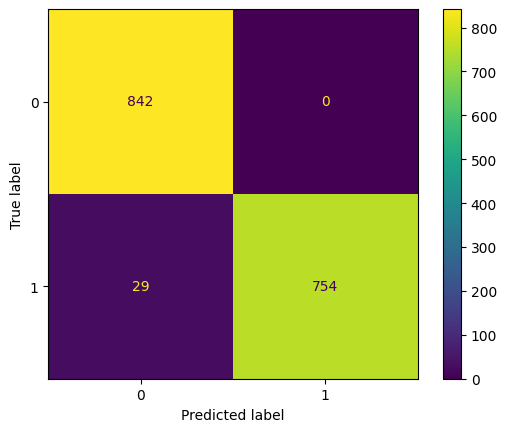

In [33]:
show_confusion_matrix(y_test, y_pred_l2)

Гипотеза 1 подтвердилась. Видим, что Accuracy и Recall чуть ниже, чем мы предсказывали - 0.982 против 0.985 и 0.963 против 0.97, соответственно. Могу обосновать это тем, что в train и test попали разные доли ядовитых и съедобных грибов.
Также видим, что базовые модели пропускают 29 ядовитых грибов как съедобные (FP), значит нам нужно уменьшать Precision в пользу Recall.

## Проверка второй гипотезы


In [34]:
proba = l2_pipe_odor.predict_proba(X_test[['odor']])[:, 1]

for t in [0.5, 0.1, 0.05, 0.03, 0.02]:
  y_pred = (proba >= t).astype(int)
  tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
  name = f'порог {t}'
  report(name, y_test, y_pred)


 порог 0.5 

Accuracy:  0.9822
Precision: 1.0000
Recall:    0.9630
F1-Score:  0.9811


 порог 0.1 

Accuracy:  0.9822
Precision: 1.0000
Recall:    0.9630
F1-Score:  0.9811


 порог 0.05 

Accuracy:  0.9822
Precision: 1.0000
Recall:    0.9630
F1-Score:  0.9811


 порог 0.03 

Accuracy:  0.5895
Precision: 0.5400
Recall:    1.0000
F1-Score:  0.7013


 порог 0.02 

Accuracy:  0.5895
Precision: 0.5400
Recall:    1.0000
F1-Score:  0.7013



Гипотеза 2 подтвердилась. Видим, что, с учетом разброса случайного разделения на тестовую и обучающую выборки, при пороге 0.5 получились примерно те цифры, которые мы предсказывали: FN = 29 (ожидали 24). При 0.03: FN = 0, FP = 667 (ожидали 680).

Наблюдаем, что при пороге выше 0.03 грибы с `odor` = `n` считаются съедобными, и только ниже или равно 0.03 считаются ядовитыми, промежуточных результатов нет.

Но цена Recall довольно высока, Accuracy и Precision падают почти вдвое.

## Проверка третьей гипотезы

In [35]:
tree_pipe_full = make_pipe(DecisionTreeClassifier(random_state=1))
l2_pipe_full = make_pipe(LogisticRegression(max_iter=1000))
l1_pipe_full = make_pipe(LogisticRegression(penalty='l1', solver='liblinear'))

models_full = {'tree': tree_pipe_full, 'l1': l1_pipe_full, 'l2': l2_pipe_full}

for name, pipe in models_full.items():
  pipe.fit(X_train, y_train)
  report(name, y_test, pipe.predict(X_test))


 tree 

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000


 l1 

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000


 l2 

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000



Проверка на выделенном тестовом массиве показала безупречный результат. Нужно проверять на кроссвалидации.

In [36]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

scores = cross_validate(
    l2_pipe_full, X_train, y_train, cv=cv,
    scoring=['accuracy', 'precision', 'recall', 'f1'],
    return_train_score=True,
)
res = pd.DataFrame(scores)
print(res.filter(like='test_'))

   test_accuracy  test_precision  test_recall  test_f1
0       1.000000             1.0     1.000000   1.0000
1       1.000000             1.0     1.000000   1.0000
2       1.000000             1.0     1.000000   1.0000
3       0.998462             1.0     0.996805   0.9984
4       1.000000             1.0     1.000000   1.0000


Кросс-валидация также показала почти идеальный результат по необходимому нам Recall.

In [37]:
param_grid = {'clf__max_depth': [1, 2, 3, 4, 5, 6, 8, None]}

grid = GridSearchCV(
    tree_pipe_full,
    param_grid,
    cv=cv,
    scoring='recall',
    return_train_score=True
)

grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('enc',
                                        OneHotEncoder(handle_unknown='ignore')),
                                       ('clf',
                                        DecisionTreeClassifier(random_state=1))]),
             param_grid={'clf__max_depth': [1, 2, 3, 4, 5, 6, 8, None]},
             return_train_score=True, scoring='recall')

In [38]:
print(grid.best_params_)
print(grid.best_score_)

res = pd.DataFrame(grid.cv_results_)
display(res[['param_clf__max_depth', 'mean_train_score', 'mean_test_score']])

{'clf__max_depth': 6}
0.9993610223642172


,param_clf__max_depth,mean_train_score,mean_test_score
0,1,0.970954,0.970952
1,2,0.954353,0.953735
2,3,0.984198,0.983092
3,4,0.997925,0.996808
4,5,0.998643,0.997766
5,6,0.999681,0.999361
6,8,1.000000,0.999361
7,None,1.000000,0.999361


Гипотеза 3 не подтвердилась. По train и test разрыв действительно минимальный, но FN минимален на глубине 6, а не 5, и все же FN остается > 0

## Проверка четвертой гипотезы

In [39]:
from sklearn.tree import plot_tree

def show_tree(pipe, max_depth=None):
    enc = pipe.named_steps['enc']
    clf = pipe.named_steps['clf']
    names = enc.get_feature_names_out()

    imp = pd.Series(clf.feature_importances_, index=names)
    by_feature = imp.groupby(lambda n: n.rsplit('_', 1)[0]).sum()
    display(by_feature.sort_values(ascending=False))

    print('глубина:', clf.get_depth(), '| листьев:', clf.get_n_leaves())

    plt.figure(figsize=(20, 12))
    plot_tree(
        clf,
        feature_names=names,
        class_names=['e', 'p'],
        filled=True,
        rounded=True,
        fontsize=10,
        max_depth=max_depth,
    )
    plt.show()

,0
odor,0.648725
stalk-root,0.170653
stalk-surface-below-ring,0.085938
spore-print-color,0.057897
stalk-color-above-ring,0.020995
stalk-color-below-ring,0.012104
cap-surface,0.001843
bruises,0.001813
gill-size,0.000034
gill-attachment,0.000000


глубина: 7 | листьев: 15


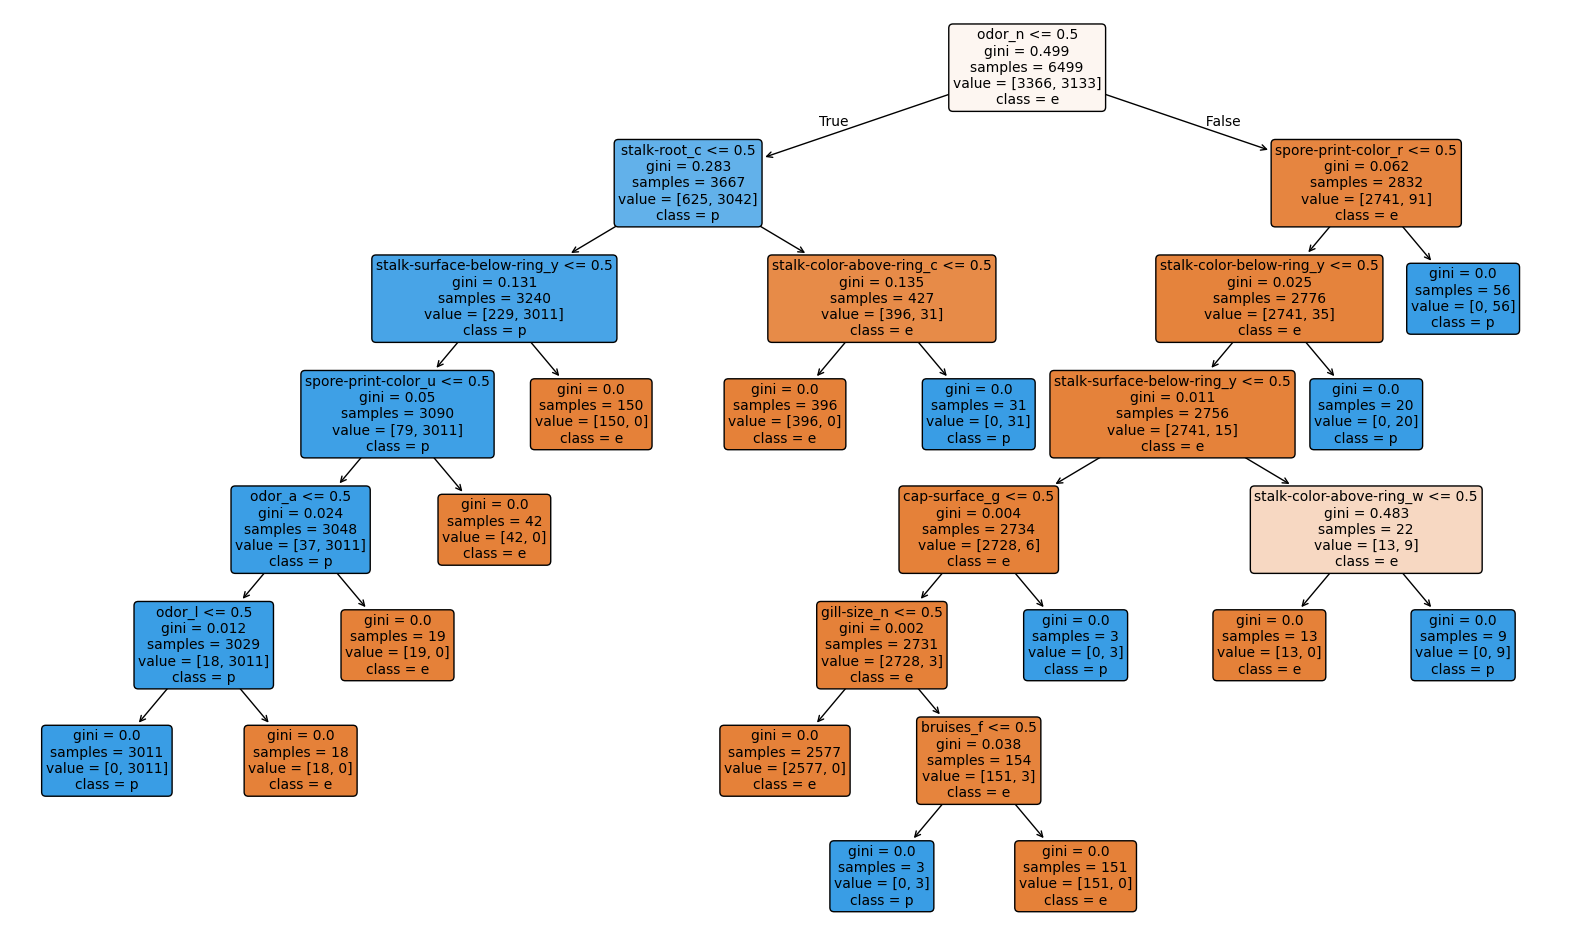

In [40]:
show_tree(tree_pipe_full)

Гипотеза 4 не подтвердилась. `odor` получил только 65% важности, мы предсказывали 90%. Остальные признаки получили соответственно больше 1% важности. Так получилось, потому что деление по `odor` в левой ветке уже не давало такой большой прирост информации.

## Проверка пятой гипотезы

In [41]:
df_train = X_train.copy()
df_train['class'] = y_train
df_train.head()

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat,class
5476,x,y,g,f,f,f,c,b,h,e,b,k,k,n,b,w,o,l,h,v,g,1
4410,f,f,e,t,n,f,c,b,u,t,b,s,s,g,w,w,o,p,n,y,d,0
223,f,f,w,t,a,f,w,n,p,t,b,s,s,w,w,w,o,p,n,v,d,0
2068,f,s,g,f,n,f,w,b,p,t,e,s,s,w,w,w,o,e,n,a,g,0
3142,f,y,g,t,n,f,c,b,w,t,b,s,s,p,p,w,o,p,k,y,d,0


In [42]:
df_train['class'] = df_train['class'].replace({1.0: 'p'})
df_train['class'] = df_train['class'].replace({0.0: 'e'})

df_train.head()

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,stalk-root,stalk-surface-above-ring,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-color,ring-number,ring-type,spore-print-color,population,habitat,class
5476,x,y,g,f,f,f,c,b,h,e,b,k,k,n,b,w,o,l,h,v,g,p
4410,f,f,e,t,n,f,c,b,u,t,b,s,s,g,w,w,o,p,n,y,d,e
223,f,f,w,t,a,f,w,n,p,t,b,s,s,w,w,w,o,p,n,v,d,e
2068,f,s,g,f,n,f,w,b,p,t,e,s,s,w,w,w,o,e,n,a,g,e
3142,f,y,g,t,n,f,c,b,w,t,b,s,s,p,p,w,o,p,k,y,d,e


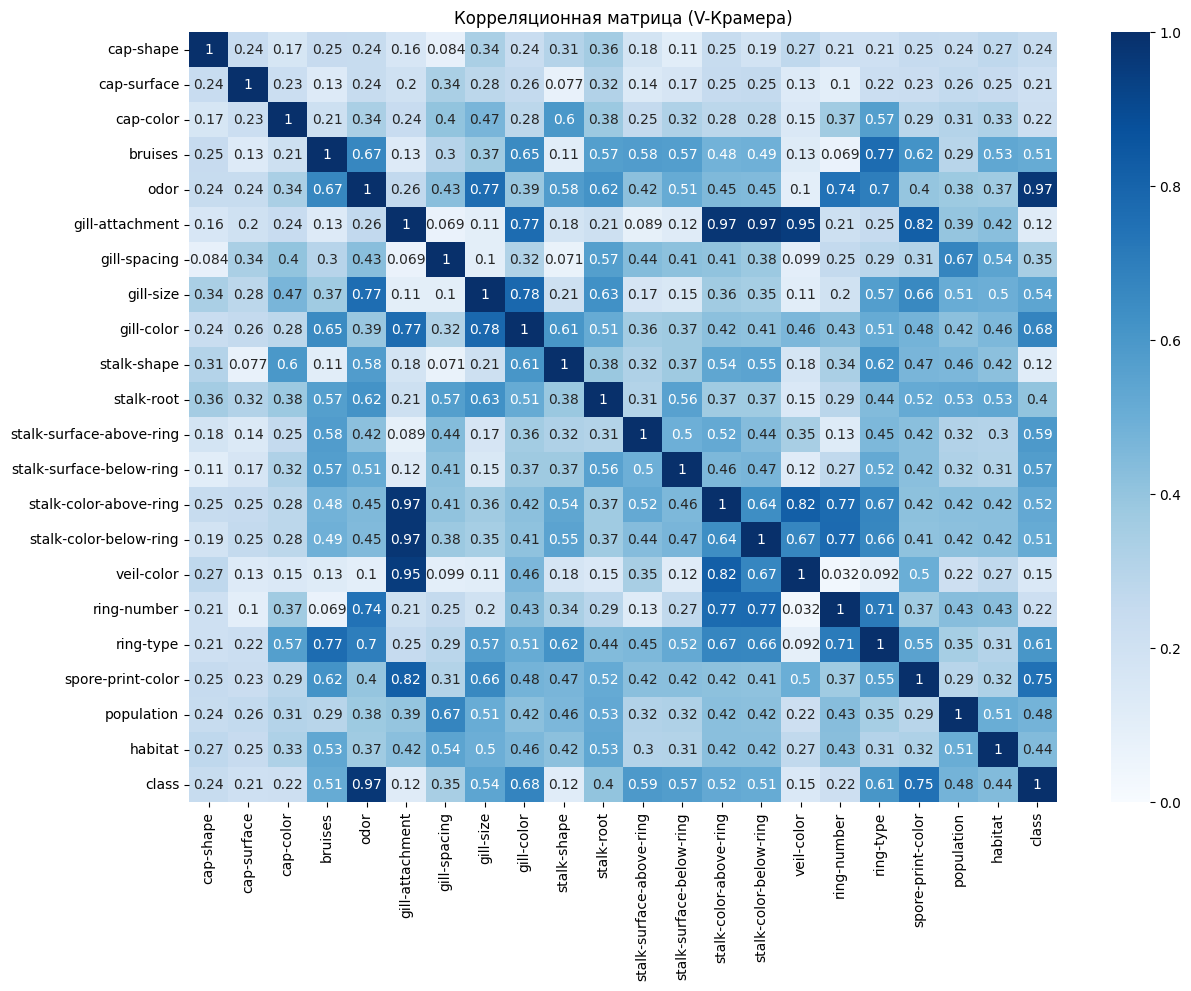

In [43]:
train_cramers = cramers_v_matrix(df_train)
train_cramers

plt.figure(figsize=(14, 10))
sns.heatmap(train_cramers, annot=True, cmap='Blues', vmin=0, vmax=1)
plt.title("Корреляционная матрица (V-Крамера)")
plt.show()

In [44]:
top_4_train_features = ['odor', 'spore-print-color', 'gill-color', 'ring-type']
top_3_train_features = top_4_train_features[:-1]

tree_pipe_top_4 = make_pipe(DecisionTreeClassifier(random_state=1))
tree_pipe_top_3 = make_pipe(DecisionTreeClassifier(random_state=1))

In [45]:
tree_pipe_top_4.fit(X_train[top_4_train_features], y_train)
y_pred_top_4 = tree_pipe_top_4.predict(X_test[top_4_train_features])
report('top 4', y_test, y_pred_top_4)


 top 4 

Accuracy:  0.9920
Precision: 1.0000
Recall:    0.9834
F1-Score:  0.9916



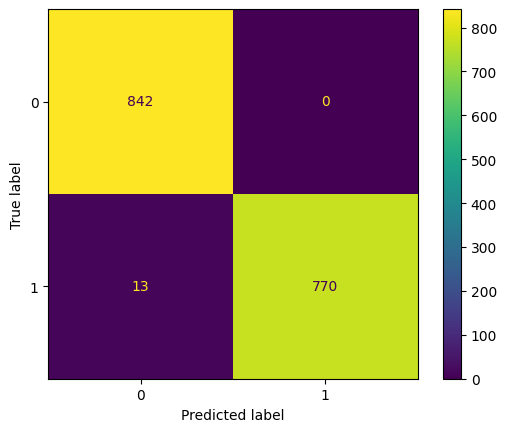

In [46]:
show_confusion_matrix(y_test, y_pred_top_4)

,0
odor,0.961285
spore-print-color,0.034779
gill-color,0.003263
ring-type,0.000673


глубина: 6 | листьев: 9


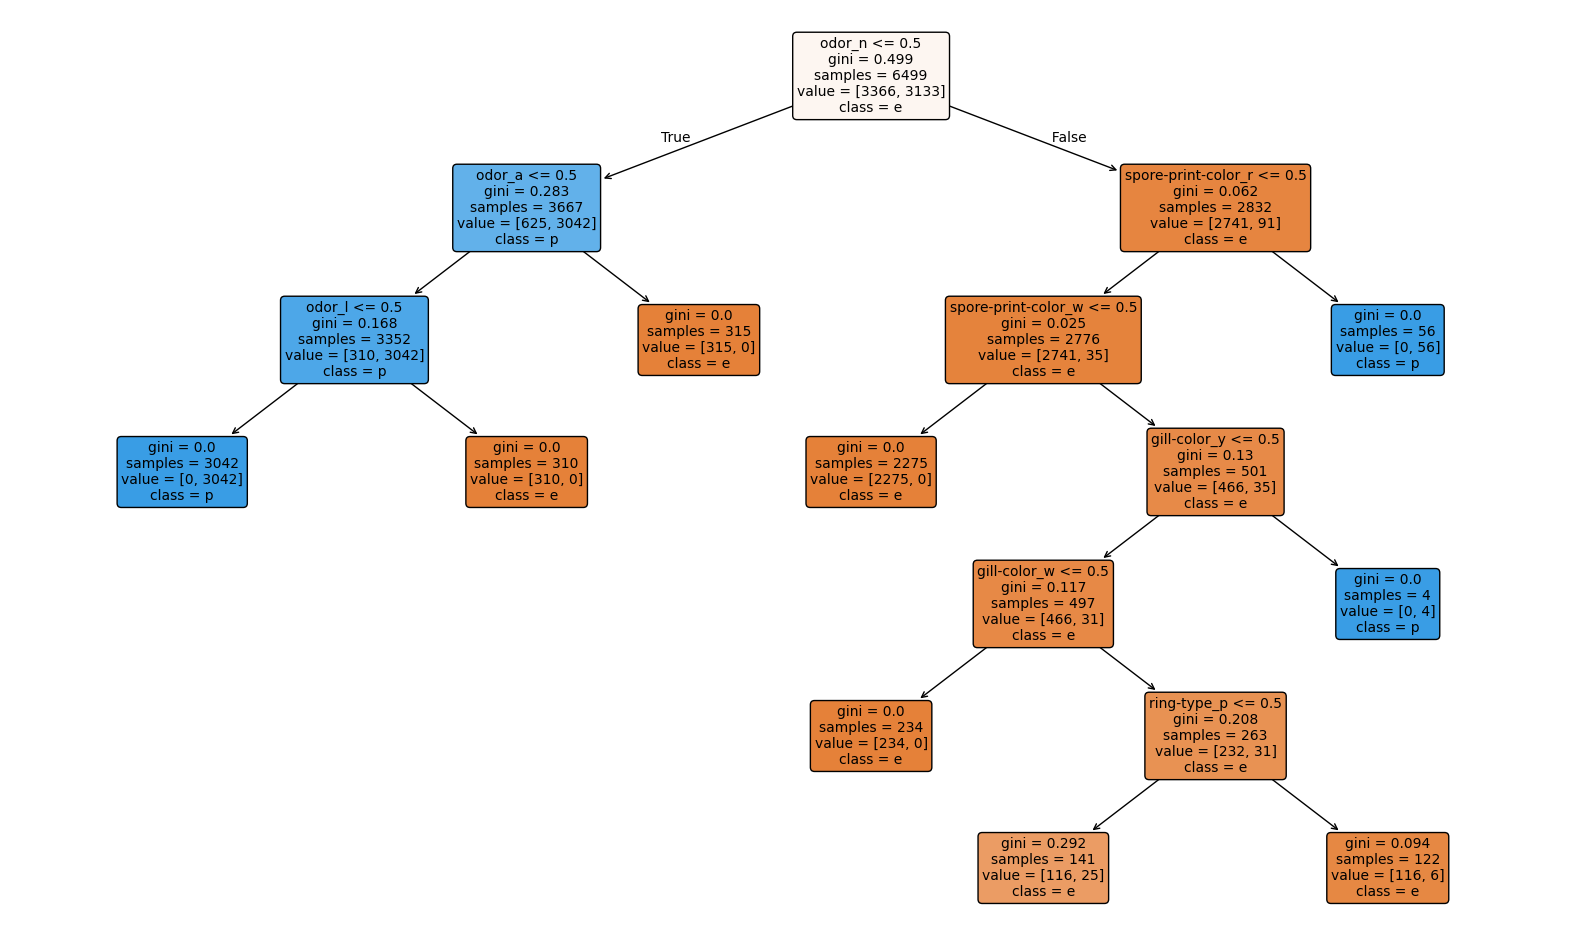

In [47]:
show_tree(tree_pipe_top_4)

In [48]:
tree_pipe_top_3.fit(X_train[top_3_train_features], y_train)
y_pred_top_3 = tree_pipe_top_3.predict(X_test[top_3_train_features])
report('top 3', y_test, y_pred_top_3)


 top 3 

Accuracy:  0.9920
Precision: 1.0000
Recall:    0.9834
F1-Score:  0.9916



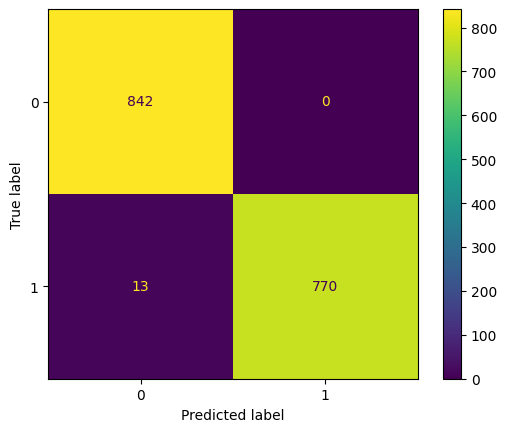

In [49]:
show_confusion_matrix(y_test, y_pred_top_3)

,0
odor,0.961932
spore-print-color,0.034803
gill-color,0.003265


глубина: 5 | листьев: 8


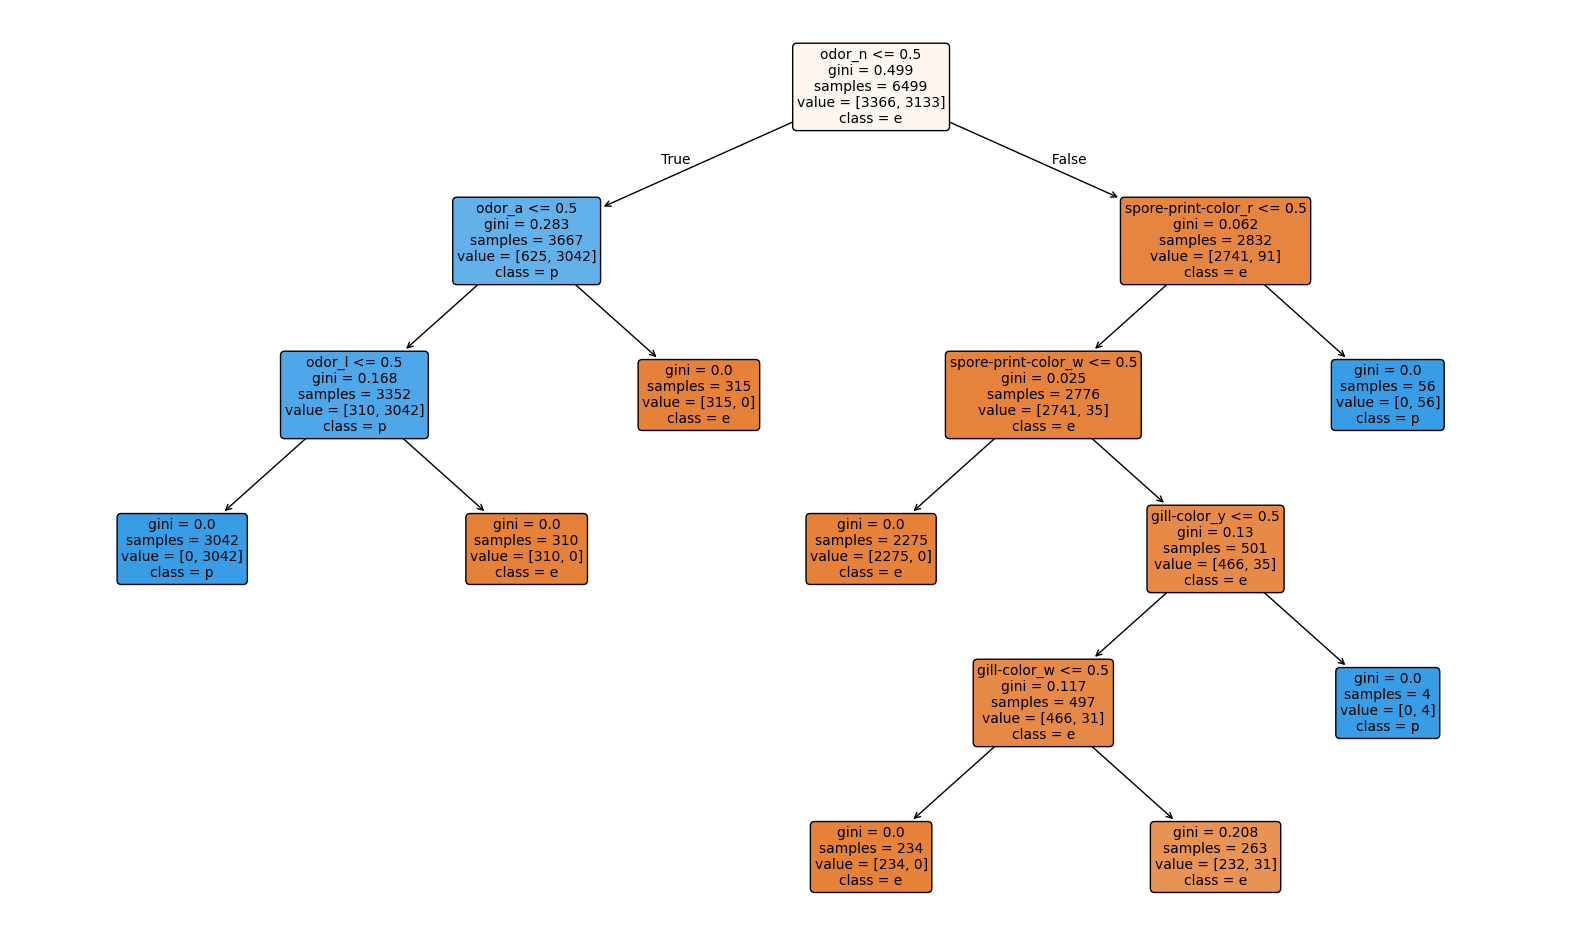

In [50]:
show_tree(tree_pipe_top_3)

Гипотеза 5 не подтвердилась. Ожидаемый топ 4 по train совпал с V-Крамера по полному датасету. На топ-4 признака мы не получили FN = 0, accuracy получили 99%. Причина этому - оставшиеся 3 признака после `odor` не разбирают эту редкую группу по `n`, для этого нужные другие признаки, которые мы увидели в 4 гипотезе (`stalk-root`, `stalk-surface-below-ring` и `stalk-color-above-ring`), которые имеют корреляцию с классом 0.4, 0.57 и 0.52, соответственно, поэтому они не попали в топ 4 признака.

# Краткие выводы
## По гипотезам:
1. Подтвердилась. Test: accuracy 0.982, recall 0.963 (ожидали 0.985 и 0.97), train почти такой же, все три модели дали одно и то же.
2. Подтвердилась. Порог ниже 0.034 дал FN = 0, FP = 667, но precision упала до 0.54. Порог работает как переключатель.
3. Не подтвердилась. Ожидали FN = 0 на глубине 5, получили recall 0.9978 на 5 и 0.9994 на 6 (с ошибками на редких группах). Разрыва train/test до глубины 6 нет.
4. Не подтвердилась. `odor` первый, но 65% вместо 90%, потому что правую ветку дерево разобрало через `stalk-root` и другие признаки.
5. Не подтвердилась. На топ-3 и топ-4 FN > 0 (accuracy 0.992), потому что рейтинг по V-Крамера не находит признаки, которые дополняют `odor`.

## По работе
В целом датасет очень хорошо классифицирует грибы и не переобучает модели, поэтому для большинства моделей лучше не ограничивать параметры и признаки.

# Сбор финальных моделей

In [51]:
tree_pipe_cv = make_pipe(DecisionTreeClassifier(random_state=1))
l2_pipe_cv = make_pipe(LogisticRegression(max_iter=1000))
l1_pipe_cv = make_pipe(LogisticRegression(penalty='l1', solver='liblinear'))

In [52]:
param_grid_lr = {'clf__C': [0.01, 0.1, 1, 10, 100]}

grid_l2 = GridSearchCV(
    l2_pipe_cv,
    param_grid_lr,
    cv=cv,
    scoring=['recall', 'precision'],
    refit='recall'
)

grid_l2.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('enc',
                                        OneHotEncoder(handle_unknown='ignore')),
                                       ('clf',
                                        LogisticRegression(max_iter=1000))]),
             param_grid={'clf__C': [0.01, 0.1, 1, 10, 100]}, refit='recall',
             scoring=['recall', 'precision'])

In [53]:
grid_l1 = GridSearchCV(
    l1_pipe_cv,
    param_grid_lr,
    cv=cv,
    scoring=['recall', 'precision'],
    refit='recall'
)

grid_l1.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('enc',
                                        OneHotEncoder(handle_unknown='ignore')),
                                       ('clf',
                                        LogisticRegression(penalty='l1',
                                                           solver='liblinear'))]),
             param_grid={'clf__C': [0.01, 0.1, 1, 10, 100]}, refit='recall',
             scoring=['recall', 'precision'])

In [54]:
grid_tree = GridSearchCV(
    tree_pipe_cv,
    {'clf__max_depth': [3, 4, 5, 6, 8, None]},
    cv=cv,
    scoring=['recall', 'precision'],
    refit='recall'
)

grid_tree.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('enc',
                                        OneHotEncoder(handle_unknown='ignore')),
                                       ('clf',
                                        DecisionTreeClassifier(random_state=1))]),
             param_grid={'clf__max_depth': [3, 4, 5, 6, 8, None]},
             refit='recall', scoring=['recall', 'precision'])

In [55]:
def summary(grid, param):
    res = pd.DataFrame(grid.cv_results_)
    return res[[param, 'mean_test_recall', 'mean_test_precision', 'std_test_recall']]

display(summary(grid_tree, 'param_clf__max_depth'))
display(summary(grid_l2, 'param_clf__C'))
display(summary(grid_l1, 'param_clf__C'))

,param_clf__max_depth,mean_test_recall,mean_test_precision,std_test_recall
0,3,0.983092,0.977325,0.028379
1,4,0.996808,0.990518,0.003349
2,5,0.997766,0.994607,0.002387
3,6,0.999361,1.000000,0.001278
4,8,0.999361,1.000000,0.001278
5,None,0.999361,1.000000,0.001278


,param_clf__C,mean_test_recall,mean_test_precision,std_test_recall
0,0.01,0.975420,0.989372,0.007120
1,0.10,0.996489,1.000000,0.002554
2,1.00,0.999361,1.000000,0.001278
3,10.00,1.000000,1.000000,0.000000
4,100.00,1.000000,1.000000,0.000000


,param_clf__C,mean_test_recall,mean_test_precision,std_test_recall
0,0.01,0.975737,0.974842,0.009664
1,0.10,0.995850,1.000000,0.002389
2,1.00,0.999042,1.000000,0.001917
3,10.00,1.000000,1.000000,0.000000
4,100.00,1.000000,1.000000,0.000000


дерево проигрывает логрегрессии по `recall` и `precision`. Ограничим C для L1 и L2 и прогоним снова.

In [56]:
param_grid_lr = {'clf__C': [2, 3, 4, 5, 6, 7, 8, 9, 10]}

grid_l2_2 = GridSearchCV(
    l2_pipe_cv,
    param_grid_lr,
    cv=cv,
    scoring=['recall', 'precision'],
    refit='recall'
)

grid_l2_2.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('enc',
                                        OneHotEncoder(handle_unknown='ignore')),
                                       ('clf',
                                        LogisticRegression(max_iter=1000))]),
             param_grid={'clf__C': [2, 3, 4, 5, 6, 7, 8, 9, 10]},
             refit='recall', scoring=['recall', 'precision'])

In [57]:
grid_l1_2 = GridSearchCV(
    l1_pipe_cv,
    param_grid_lr,
    cv=cv,
    scoring=['recall', 'precision'],
    refit='recall'
)

grid_l1_2.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('enc',
                                        OneHotEncoder(handle_unknown='ignore')),
                                       ('clf',
                                        LogisticRegression(penalty='l1',
                                                           solver='liblinear'))]),
             param_grid={'clf__C': [2, 3, 4, 5, 6, 7, 8, 9, 10]},
             refit='recall', scoring=['recall', 'precision'])

In [58]:
display(summary(grid_l2_2, 'param_clf__C'))
display(summary(grid_l1_2, 'param_clf__C'))

,param_clf__C,mean_test_recall,mean_test_precision,std_test_recall
0,2,0.999361,1.0,0.001278
1,3,0.999681,1.0,0.000639
2,4,1.000000,1.0,0.000000
3,5,1.000000,1.0,0.000000
4,6,1.000000,1.0,0.000000
5,7,1.000000,1.0,0.000000
6,8,0.999681,1.0,0.000639
7,9,0.999681,1.0,0.000639
8,10,1.000000,1.0,0.000000


,param_clf__C,mean_test_recall,mean_test_precision,std_test_recall
0,2,1.0,1.0,0.0
1,3,1.0,1.0,0.0
2,4,1.0,1.0,0.0
3,5,1.0,1.0,0.0
4,6,1.0,1.0,0.0
5,7,1.0,1.0,0.0
6,8,1.0,1.0,0.0
7,9,1.0,1.0,0.0
8,10,1.0,1.0,0.0


In [59]:
best = grid_l1_2.best_estimator_
report('final l1', y_test, best.predict(X_test))


 final l1 

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000



L1 достигает идеала при меньшем C. При этом L2 прыгает на разных C, а L1 стабильна, она лучше подходит для этого набора данных.

In [60]:
print(grid_l1_2.best_params_)
coef = grid_l1_2.best_estimator_.named_steps['clf'].coef_[0]
print((coef != 0).sum(), 'ненулевых весов из', len(coef))

{'clf__C': 2}
26 ненулевых весов из 116


Узнаем, какие признаки не зануляются

In [61]:
pipe = grid_l1.best_estimator_
names = pipe.named_steps['enc'].get_feature_names_out()
coef = pipe.named_steps['clf'].coef_[0]

kept_features = sorted({n.rsplit('_', 1)[0] for n in names[coef != 0]})
print(len(kept_features), kept_features)

16 ['bruises', 'cap-color', 'cap-shape', 'cap-surface', 'gill-color', 'gill-size', 'gill-spacing', 'habitat', 'odor', 'population', 'ring-number', 'spore-print-color', 'stalk-color-below-ring', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring']


Обучим итоговую модель

In [62]:
final_pipe = make_pipe(LogisticRegression(penalty='l1', solver='liblinear', random_state=1))

In [63]:
grid_final_pipe = GridSearchCV(
    final_pipe,
    {'clf__C': [1, 2, 3, 5, 10]},
    cv=cv,
    scoring=['recall', 'precision'],
    refit='recall',
)
grid_final_pipe.fit(X_train[kept_features], y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=1, shuffle=True),
             estimator=Pipeline(steps=[('enc',
                                        OneHotEncoder(handle_unknown='ignore')),
                                       ('clf',
                                        LogisticRegression(penalty='l1',
                                                           random_state=1,
                                                           solver='liblinear'))]),
             param_grid={'clf__C': [1, 2, 3, 5, 10]}, refit='recall',
             scoring=['recall', 'precision'])

In [64]:
display(summary(grid_final_pipe, 'param_clf__C'))

,param_clf__C,mean_test_recall,mean_test_precision,std_test_recall
0,1,0.999042,1.0,0.001917
1,2,1.000000,1.0,0.000000
2,3,1.000000,1.0,0.000000
3,5,1.000000,1.0,0.000000
4,10,1.000000,1.0,0.000000


In [65]:
grid_final_pipe.best_params_

{'clf__C': 2}

In [66]:
final_model = grid_final_pipe.best_estimator_
report('final L1 (урезанная)', y_test, final_model.predict(X_test[kept_features]))


 final L1 (урезанная) 

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000



In [67]:
import joblib
joblib.dump(final_model, 'mushroom_model.joblib')
joblib.dump(kept_features, 'mushroom_features.joblib')

['mushroom_features.joblib']

In [68]:
sample = X_test[kept_features].iloc[[0]]
final_model.predict_proba(sample)

array([[0.00176702, 0.99823298]])

In [69]:
y_test[0]

np.int64(1)

Для дальнейшей работы хотел бы попробовать отобрать параметры, которые может увидеть обычный человек при исследовании гриба и обучить модель на них. Это позволит сделать формочку для любого человека для проверки гриба на съедобность.